# Tasca S9.01. Visualització de Dades amb Python i Power BI

In [1]:
# comprovo que la connexió local des de Colab arriba efectivament al meu ordinador, no als servidors de Google
import os
import socket
import sys

print("Equip:", socket.gethostname())
print("Python:", sys.executable)
print("Usuari:", os.getenv("USERNAME") or os.getenv("USER"))

Equip: ESFSALT-L5410
Python: c:\Users\FDR\anaconda3\envs\test\python.exe
Usuari: FDR


In [2]:
# importo les llibreries que faré servir per a l'anàlisi i la visualització
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# importo getpass per poder escriure la contrasenya de manera oculta, sense que quedi visible al codi
from getpass import getpass
from sqlalchemy import create_engine

In [3]:
# instal·lo les llibreries necessàries per connectar Python amb una base de dades MySQL
%pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


In [4]:
# em demana la contrasenya de MySQL en executar la cel·la, sense mostrar-la per pantalla
contrasenya = getpass("Contrasenya de MySQL: ")

# defineixo les dades de connexió (host, port, usuari i nom de la base de dades)
host = 'localhost'
port = 3306
usuari = 'root'
base_dades = 'transactions_star'

# afegeixo connect_timeout perquè, si no pot connectar, falli amb un error clar en lloc de quedar-se penjat
cadena_connexio = f"mysql+pymysql://{usuari}:{contrasenya}@{host}:{port}/{base_dades}?connect_timeout=10"
motor = create_engine(cadena_connexio)

# faig una consulta senzilla de prova per confirmar que la connexió funciona
df_prova = pd.read_sql("SHOW TABLES;", motor)
df_prova

,Tables_in_transactions_star
0,companies
1,credit_cards
2,estat_targetes
3,products
4,transactions
5,users
6,vistamarketing


## Nivell 1 - Visualització analítica guiada en Python

### Exercici 1: Preguntes analítiques directes

L'equip de direcció vol una primera lectura de l'activitat transaccional sense necessitat de combinar dades d'altres àrees del negoci: només amb el registre de transaccions ja es poden respondre preguntes clau sobre volum, usuaris i patrons horaris.

#### Pregunta 1 — Com evoluciona el nombre de transaccions al llarg del temps?

**Algoritme:**
1. Carrego la taula de transaccions des de MySQL a un dataframe.
2. Identifico la columna temporal (timestamp de la transacció) i decideixo el nivell d'agregació (dia, setmana o mes, segons el rang de dates disponible).
3. Compto el nombre de transaccions per aquest període temporal.
4. Ordeno el resultat cronològicament.
5. Represento l'evolució amb un gràfic de línies.

In [5]:
# carrego la taula de transaccions des de MySQL a un dataframe
df_transaccions = pd.read_sql("SELECT * FROM transactions;", motor)
df_transaccions.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.1999,1.43554,34.17,72.25,0.00,online,SUMMER_TRAVEL,mobile,0,,59.95
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.7573,-95.37960,16.10,22.47,0.00,store,SUMMER_TRAVEL,pos,1,,1157.10
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.5489,-113.50300,1.05,14.45,0.00,store,NO_CAMPAIGN,pos,0,,540.32
3,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.2084,5.69081,25.31,25.96,8.99,marketplace,WINTER_SALE,desktop,0,,28.52
4,0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,CcU-3358,b-2598,2023-09-23 04:51:43,317.97,0,"35, 33, 19",215,53.5535,-113.49900,2.87,26.25,0.00,store,NO_CAMPAIGN,pos,0,,539.82


In [6]:
# converteixo la columna timestamp a tipus data/hora, ja que probablement ve com a text
df_transaccions['timestamp'] = pd.to_datetime(df_transaccions['timestamp'])

# comprovo el rang de dates disponible, per confirmar quin nivell d'agregació té sentit
print(f"Des de: {df_transaccions['timestamp'].min()}")
print(f"Fins a: {df_transaccions['timestamp'].max()}")

Des de: 2015-01-01 00:40:23
Fins a: 2024-12-31 23:31:55


In [7]:
# creo una columna amb el mes de cada transacció (agafant el primer dia de cada mes com a referència)
df_transaccions['mes'] = df_transaccions['timestamp'].dt.to_period('M')

# compto el nombre de transaccions per mes i ordeno cronològicament
transaccions_per_mes = df_transaccions.groupby('mes').size().sort_index()

transaccions_per_mes

mes
2015-01    818
2015-02    816
2015-03    835
2015-04    829
2015-05    812
          ... 
2024-08    824
2024-09    827
2024-10    823
2024-11    816
2024-12    871
Freq: M, Length: 120, dtype: int64

<Axes: title={'center': 'Evolució del nombre de transaccions per mes'}, xlabel='mes'>

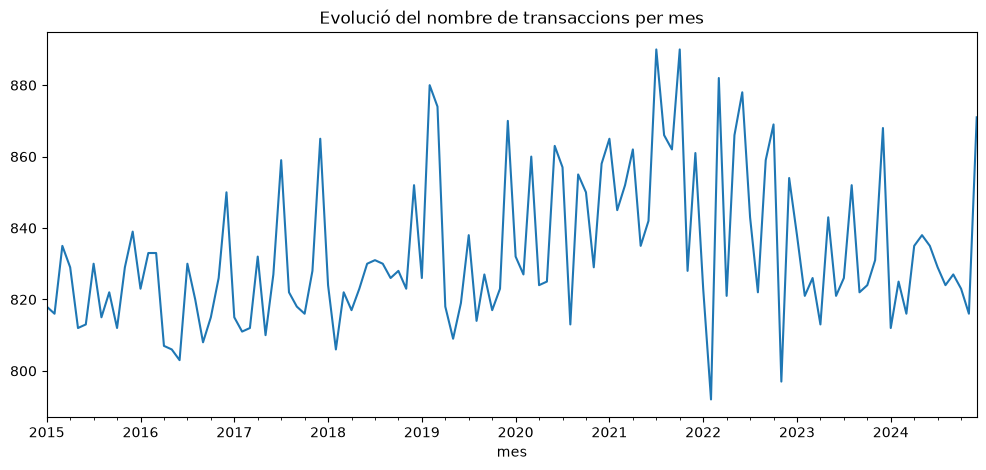

In [8]:
# converteixo l'índex de període a data (millor per representar a l'eix X) i dibuixo l'evolució
transaccions_per_mes.index = transaccions_per_mes.index.to_timestamp()
transaccions_per_mes.plot(kind='line', figsize=(12, 5), title='Evolució del nombre de transaccions per mes')

**Interpretació**

El volum mensual de transaccions es manté molt estable al llarg dels 10 anys analitzats (aproximadament 800-880 transaccions/mes), sense una tendència clara de creixement ni de declivi. Això suggereix un negoci amb una base d'activitat consolidada més que en fase d'expansió accelerada, i és un bon punt de partida per buscar patrons més fins (estacionalitat, dies de la setmana) en lloc d'una tendència general.

In [9]:
# codi proposat per la IA de Colab, mantingut aquí a efectes de comparació (comentat perquè dona error en executar-se)
# import matplotlib.pyplot as plt
#
# # Create a bar plot for monthly transaction evolution
# plt.figure(figsize=(15, 6))
# transaccions_per_mes.plot(kind='bar', figsize=(15, 6), title='Evolució del nombre de transaccions per mes (Bar Plot)')
# plt.xlabel('Mes')
# plt.ylabel('Nombre de Transaccions')
# plt.xticks(rotation=45, ha='right')
# plt.tight_layout()
# plt.show()

**Comparació: proposta pròpia vs. proposta de la IA**

La IA ha proposat substituir el gràfic de línies per un gràfic de barres. Per a aquesta pregunta concreta (evolució temporal contínua al llarg de 120 mesos), és un **empitjorament**, no una millora:

- Un gràfic de barres és adequat per comparar un nombre reduït de categories discretes, no per representar una sèrie temporal contínua amb 120 punts: amb tantes barres, l'eix X queda saturat i les etiquetes es tornen il·legibles fins i tot girant-les 45 graus.
- El gràfic de línies original comunica millor precisament el que es demanava a la pregunta —"com evoluciona"—, ja que la línia connecta visualment un punt amb el següent i permet detectar tendències, estabilitat o canvis de patró d'un cop d'ull; el de barres, en canvi, converteix cada mes en una unitat aïllada i dificulta veure la continuïtat temporal.
- A més, el codi proposat (adjunt més amunt, comentat perquè no s'executi) ni tan sols arriba a funcionar correctament: dona un `ValueError` per una incompatibilitat interna de pandas entre l'índex de dates mensuals i el mode de gràfic de barres, evidenciant que la proposta no s'ha adaptat al context real de les dades ja preparades.
- Es manté, doncs, el gràfic de línies com a visualització definitiva per a aquesta pregunta.

#### Pregunta 2 — Quins usuaris generen més volum de facturació?

**Algoritme:**
1. Agrupo les transaccions per usuari i sumo l'import (`amount`) de totes les seves transaccions.
2. Ordeno els usuaris de major a menor volum total.
3. Selecciono els 15 primers.
4. Represento el resultat amb un gràfic de barres horitzontal amb Seaborn.

In [10]:
# agrupo per usuari, sumo l'import total facturat i ordeno de major a menor
facturacio_per_usuari = (
    df_transaccions[df_transaccions['declined'] == 0]
    .groupby('user_id')
    ['amount'].sum()
    .sort_values(ascending=False)
)

# em quedo amb els 15 usuaris amb més volum de facturació
top15_usuaris = facturacio_per_usuari.head(15).reset_index()
top15_usuaris.columns = ['user_id', 'facturacio_total']

top15_usuaris

,user_id,facturacio_total
0,289,47332.90
1,318,46393.44
2,455,40594.55
3,417,37393.91
4,185,34560.87
5,285,33217.28
6,454,29528.42
7,349,27835.38
8,193,27076.83
9,317,22484.76


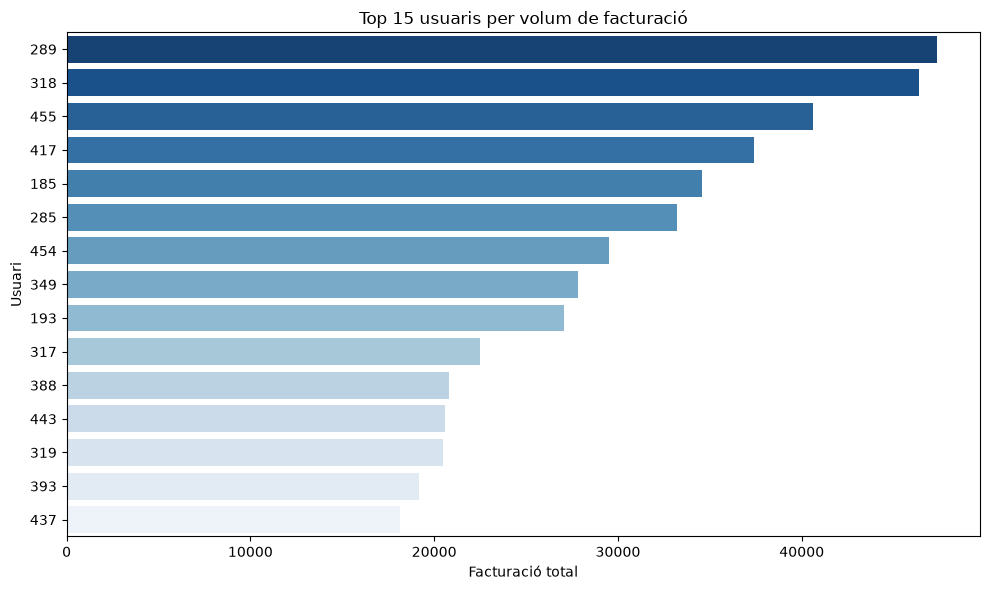

In [11]:
# converteixo user_id a text perquè Seaborn el tracti com una categoria (una barra per usuari), no com un eix numèric continu
top15_usuaris['user_id'] = top15_usuaris['user_id'].astype(str)

# dibuixo un gràfic de barres horitzontal amb els 15 usuaris de més facturació
plt.figure(figsize=(10, 6))
sns.barplot(data=top15_usuaris, x='facturacio_total', y='user_id', order=top15_usuaris['user_id'], hue='user_id', palette='Blues_r', legend=False)
plt.title('Top 15 usuaris per volum de facturació')
plt.xlabel('Facturació total')
plt.ylabel('Usuari')
plt.tight_layout()
plt.show()

Aquesta és una visualització alternativa amb un gràfic de barres vertical.

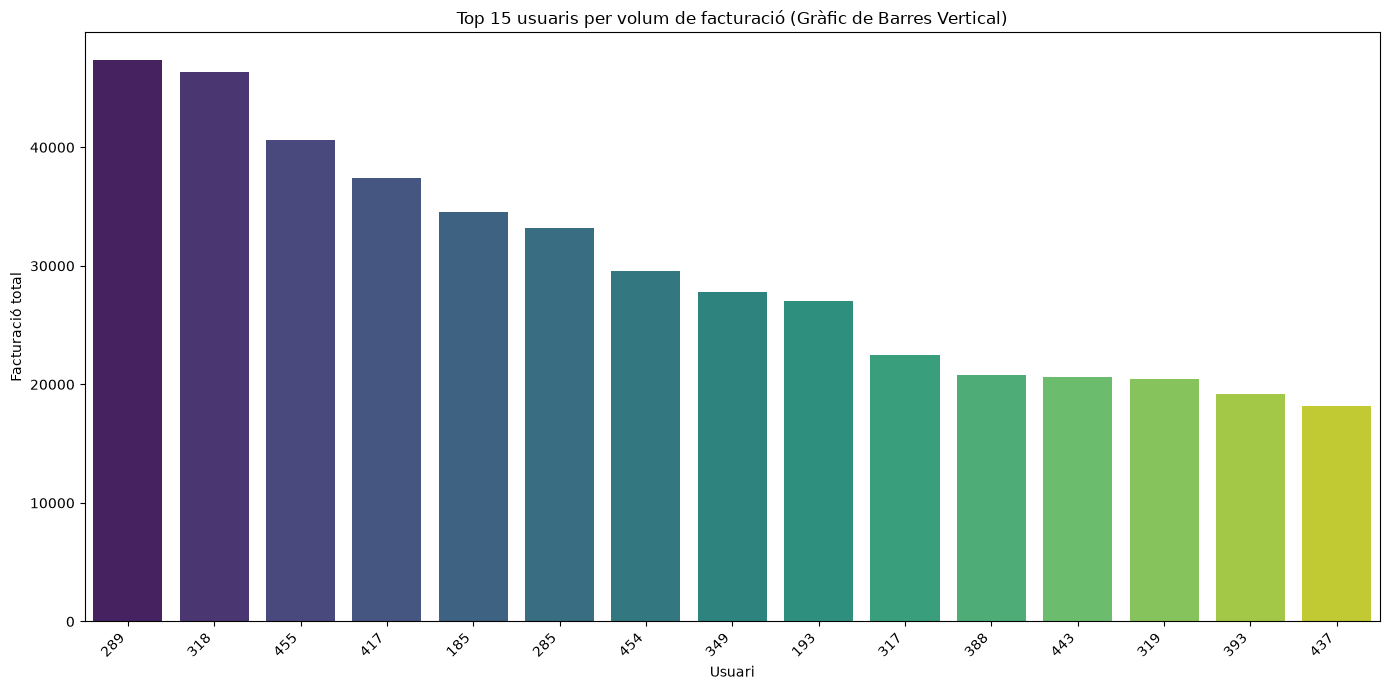

In [12]:
plt.figure(figsize=(14, 7))
sns.barplot(data=top15_usuaris, x='user_id', y='facturacio_total', hue='user_id', palette='viridis', legend=False)
plt.title('Top 15 usuaris per volum de facturació (Gràfic de Barres Vertical)')
plt.xlabel('Usuari')
plt.ylabel('Facturació total')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparació: proposta pròpia vs. proposta de la IA**

La IA ha proposat el mateix tipus de gràfic (barres) però en orientació vertical i amb la paleta `viridis` en lloc de `Blues_r`. És una **millora parcial**:

- **Punt a favor de la proposta de la IA**: la paleta `viridis` assigna colors molt diferenciats a cada usuari, mentre que `Blues_r` fa que els usuaris amb menys facturació (les últimes barres) quedin en un blau molt clar, gairebé confós amb el fons blanc — un problema real de llegibilitat que caldria corregir. Tot i que, per altra banda, els colors poden distreure l'atenció del lector i només s'haurien d'utilitzar quan signifiquen alguna cosa, com per exemple, una altra variable a tenir en compte.
- **Punt a favor de la proposta pròpia**: l'orientació horitzontal aprofita millor l'espai amb 15 categories, ja que els noms d'usuari es llegeixen directament a l'eix sense haver de girar el text 45 graus (com fa la proposta vertical de la IA), i horitzontal és, en general, l'orientació recomanada quan hi ha bastants categories amb noms o etiquetes llargues. Els colors poden distreure l'atenció del lector, només s'haurien d'utilitzar quan signifiquen alguna cosa, i en aquest cas no signifiquen res.
- **Decisió final**: es manté l'orientació horitzontal (millor per a 15 categories) però es canvia la paleta de colors de `Blues_r` a una amb millor contrast per a totes les barres, no només les primeres — resolent el problema de llegibilitat que la IA ha posat en evidència, sense heretar el problema d'etiquetes girades de la seva proposta.

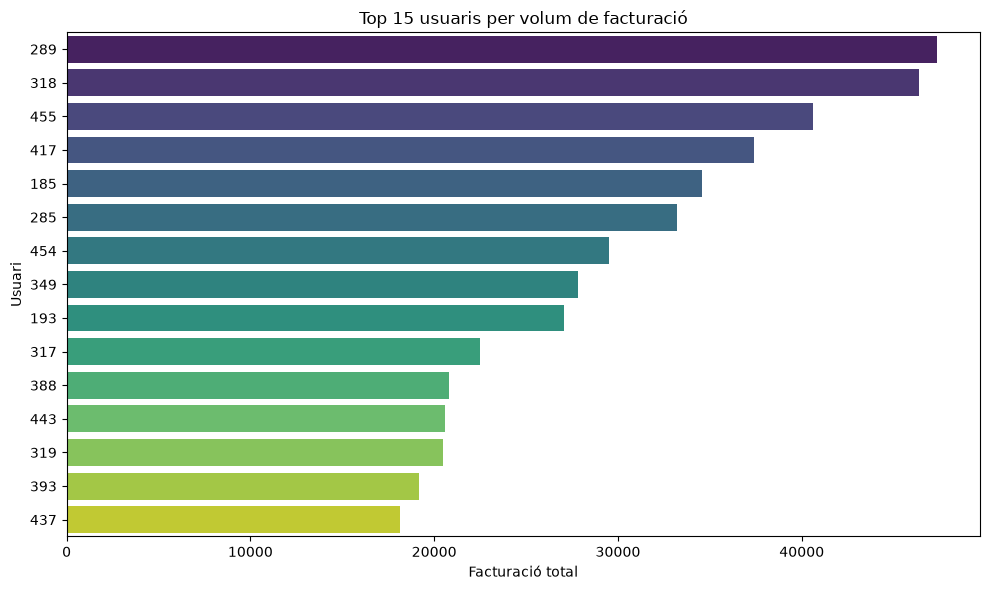

In [13]:
# dibuixo el gràfic de barres horitzontal definitiu, amb una paleta de millor contrast per a totes les barres
plt.figure(figsize=(10, 6))
sns.barplot(data=top15_usuaris, x='facturacio_total', y='user_id', order=top15_usuaris['user_id'], hue='user_id', palette='viridis', legend=False)
plt.title('Top 15 usuaris per volum de facturació')
plt.xlabel('Facturació total')
plt.ylabel('Usuari')
plt.tight_layout()
plt.show()

#### Pregunta 3 — Hi ha diferències en la distribució de l'import segons l'hora del dia i si la transacció ha estat acceptada o rebutjada?

**Algoritme:**
1. Creo una columna amb l'hora del dia a partir del `timestamp`.
2. Dibuixo un violinplot amb Seaborn: l'hora a l'eix X, l'import a l'eix Y, i el color (`hue`) segons si la transacció ha estat acceptada o rebutjada.
3. Activo `split` per comparar acceptades i rebutjades dins del mateix violí, i `inner='quartile'` per mostrar la mediana i els quartils.

In [14]:
# creo una columna amb l'hora del dia (0-23) a partir del timestamp
df_transaccions['hora'] = df_transaccions['timestamp'].dt.hour

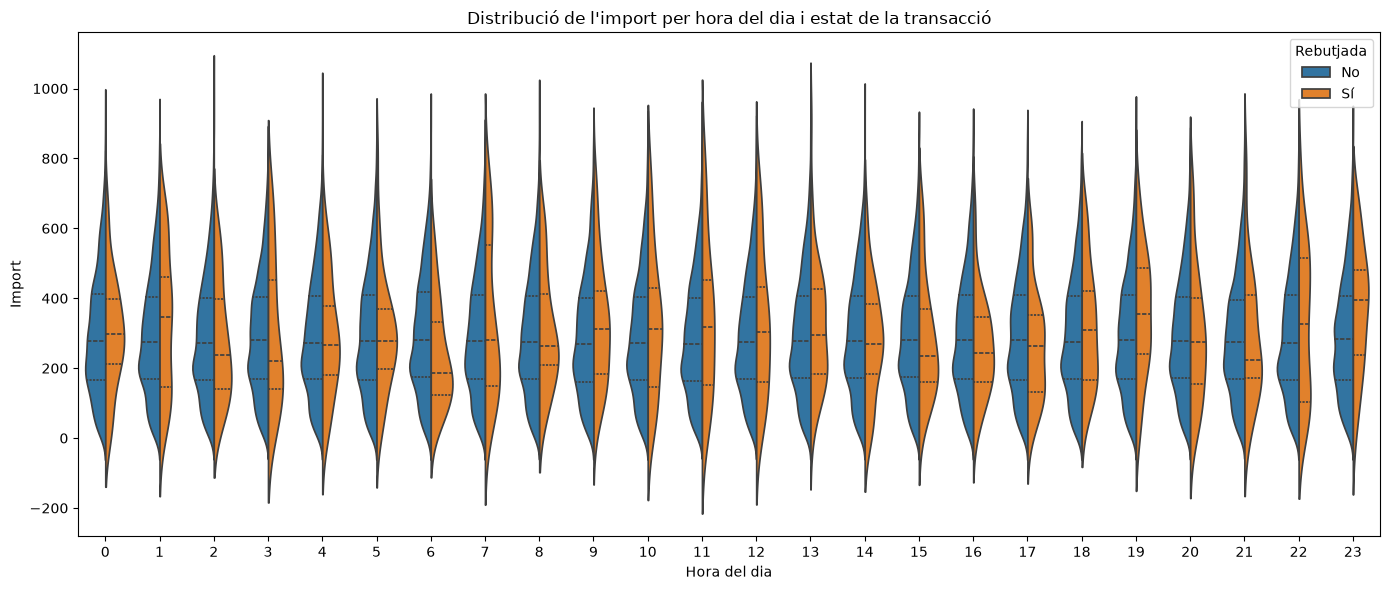

In [15]:
# dibuixo el violinplot: hora a l'eix X, import a l'eix Y, dividit per si ha estat rebutjada o no
plt.figure(figsize=(14, 6))
ax = sns.violinplot(data=df_transaccions, x='hora', y='amount', hue='declined', split=True, inner='quartile')

# recupero només els elements de color del gràfic (blau/taronja) i els renomeno correctament
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['No', 'Sí'], title='Rebutjada')

plt.title("Distribució de l'import per hora del dia i estat de la transacció")
plt.xlabel('Hora del dia')
plt.ylabel('Import')
plt.tight_layout()
plt.show()

In [16]:
# calculo estadístics clau (mediana, mitjana, quartils) de l'import, agrupats per hora i per si ha estat rebutjada
resum_hora_estat = df_transaccions.groupby(['hora', 'declined'])['amount'].agg(['median', 'mean', 'std', 'count']).round(2)
resum_hora_estat

median    mean     std  count
hora declined                               
0    0         276.74  295.65  170.69   4085
     1         299.02  294.50  161.41     40
1    0         273.64  292.11  168.58   4169
     1         347.45  332.20  199.34     52
2    0         271.75  288.86  166.09   4050
     1         236.89  275.45  167.17     37
3    0         281.14  292.81  164.05   4178
     1         219.96  296.36  209.80     32
4    0         271.47  291.00  166.85   4161
     1         266.96  287.78  166.91     32
5    0         277.00  293.19  168.73   4238
     1         277.73  293.87  165.74     35
6    0         279.80  299.18  169.25   4128
     1         186.87  238.35  148.68     41
7    0         276.38  294.56  168.12   4079
     1         280.05  327.79  220.73     36
8    0         275.96  292.33  166.55   4179
     1         262.28  303.08  164.41     33
9    0         269.74  288.42  166.64   4101
     1         313.02  324.05  178.37     50
10   0         271.76  290.35  167.88   4120
     1         312.44  327.87  201.15     28
11   0         268.95  286.19  163.92   4131
     1         317.01  338.40  220.31     30
12   0         274.70  292.11  165.05   4171
     1         303.74  321.75  203.00     35
13   0         276.74  293.66  166.46   4234
     1         295.38  314.59  175.38     47
14   0         277.67  293.66  165.85   4165
     1         269.99  276.22  159.96     35
15   0         281.47  297.54  166.77   4140
     1         233.78  282.87  168.56     34
16   0         280.35  296.35  167.30   4112
     1         242.62  262.11  142.84     38
17   0         279.27  294.81  168.62   4097
     1         264.74  262.37  155.49     38
18   0         273.51  292.22  168.96   4131
     1         308.95  318.91  169.11     37
19   0         281.65  294.61  166.25   4004
     1         354.76  353.48  175.30     30
20   0         278.96  294.68  165.42   4038
     1         274.90  288.09  186.03     35
21   0         274.54  289.38  161.67   4229
     1         222.38  283.48  185.09     36
22   0         270.78  291.15  167.54   4073
     1         327.81  326.16  214.71     41
23   0         282.40  293.82  167.65   4098
     1         395.07  373.12  177.11     36

In [17]:
# comparo, per a cada hora, la mediana de l'import de les acceptades vs. les rebutjades
comparacio = df_transaccions.groupby(['hora', 'declined'])['amount'].median().unstack()
comparacio.columns = ['Mediana acceptades', 'Mediana rebutjades']
comparacio['diferencia'] = comparacio['Mediana rebutjades'] - comparacio['Mediana acceptades']
comparacio

,Mediana acceptades,Mediana rebutjades,diferencia
hora,,,
0,276.740,299.020,22.280
1,273.640,347.450,73.810
2,271.750,236.890,-34.860
3,281.140,219.955,-61.185
4,271.470,266.965,-4.505
5,276.995,277.730,0.735
6,279.805,186.870,-92.935
7,276.380,280.050,3.670
8,275.960,262.280,-13.680


**Interpretació**

No s'observa un patró horari clar ni consistent en la diferència d'import entre transaccions acceptades i rebutjades: la diferència de mediana canvia de signe constantment al llarg del dia (per exemple, +112€ a les 23h però -93€ a les 6h), sense cap tendència que es mantingui durant diverses hores seguides.

Aquesta volatilitat s'explica en bona part per la mida de la mostra: cada hora té entre ~4.000 i ~4.200 transaccions acceptades, però només 28-52 rebutjades. Amb mostres tan petites, la mediana de les rebutjades és molt sensible a uns pocs casos concrets, i les diferències que semblen grans (com les 92€ de les 6h) no es poden considerar un patró horari fiable, sinó soroll estadístic derivat de la baixa mostra.

En conclusió: l'import de la transacció no sembla un factor determinant de si serà rebutjada o no, i tampoc hi ha una franja horària concreta amb més risc de rebuig per import. Convindria explorar altres variables (com `is_international` o `channel`) per entendre millor què explica els rebutjos.

#### Pregunta 4 — Quins dies de la setmana es concentra més activitat de venda?

**Algoritme:**
1. Extrec el dia de la setmana a partir del `timestamp` de cada transacció.
2. Compto el nombre de transaccions per dia de la setmana.
3. Ordeno el resultat seguint l'ordre natural de la setmana (dilluns a diumenge), no per volum.
4. Represento el resultat amb un gràfic de barres.

In [18]:
# extrec el nom del dia de la setmana de cada transacció
df_transaccions['dia_setmana'] = df_transaccions['timestamp'].dt.day_name()

# defineixo l'ordre natural dels dies, ja que per defecte sortirien per ordre alfabètic
ordre_dies = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# compto transaccions per dia i les ordeno segons l'ordre natural de la setmana
transaccions_per_dia = (
    df_transaccions[df_transaccions['declined'] == 0]['dia_setmana']
    .value_counts()
    .reindex(ordre_dies)
)

transaccions_per_dia

dia_setmana
Monday       13996
Tuesday      14045
Wednesday    14152
Thursday     14388
Friday       14138
Saturday     14221
Sunday       14171
Name: count, dtype: int64

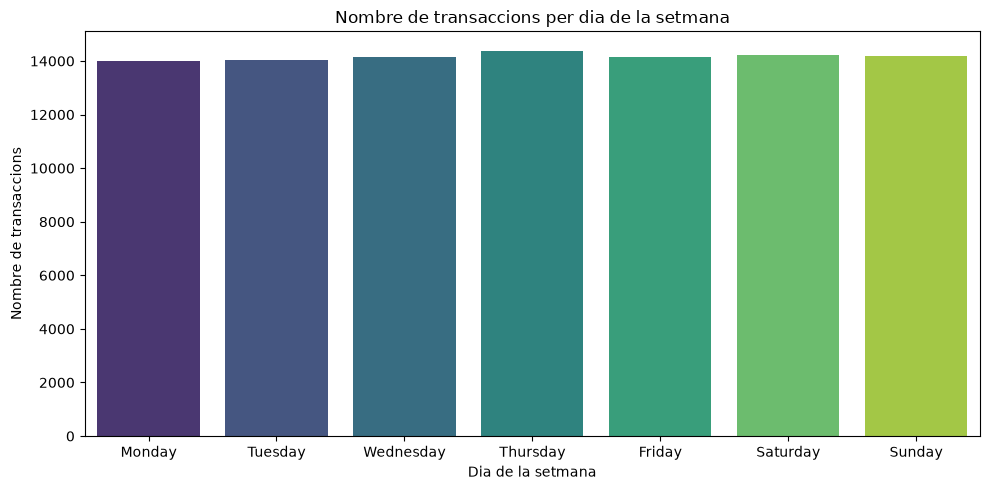

In [19]:
# dibuixo un gràfic de barres amb el nombre de transaccions per dia de la setmana
plt.figure(figsize=(10, 5))
sns.barplot(
    x=transaccions_per_dia.index, 
    y=transaccions_per_dia.values, 
    hue=transaccions_per_dia.index, 
    palette='viridis', 
    legend=False
)
plt.title('Nombre de transaccions per dia de la setmana')
plt.xlabel('Dia de la setmana')
plt.ylabel('Nombre de transaccions')
plt.tight_layout()
plt.show()

**Interpretació**

L'activitat transaccional es reparteix de manera molt homogènia al llarg de la setmana: el dia amb menys transaccions (dilluns, 14.122) i el dia amb més (dijous, 14.516) difereixen en menys d'un 3%. No hi ha, per tant, una concentració clara de vendes en cap dia concret ni un patró de "cap de setmana fort" o "entre setmana fort" — el negoci manté un volum pràcticament constant els 7 dies, cosa que suggereix un tipus de consum no estacional a nivell setmanal (a diferència del que es podria esperar, per exemple, en un comerç físic amb pics els caps de setmana).

### Exercici 2: Preguntes analítiques complexes

A diferència de l'exercici anterior, aquestes preguntes ja no es poden respondre amb una sola taula: cal combinar informació de transaccions amb la de companyies, productes o usuaris per obtenir una visió de negoci més completa, identificant dependències, estacionalitat i patrons de comportament.

#### Pregunta 1 — Depenem excessivament d'un nombre reduït de països de companyies venedores?

**Algoritme:**
1. Combino la taula de transaccions amb la de companyies, per saber a quin país pertany cada companyia venedora.
2. Agrupo la facturació total per país.
3. Ordeno els països de major a menor facturació.
4. Calculo el percentatge acumulat sobre el total.
5. Represento el resultat amb un gràfic que permeti veure tant la facturació per país com la concentració acumulada.

In [20]:
# carrego la taula de companyies des de MySQL
df_companies = pd.read_sql("SELECT * FROM companies;", motor)
df_companies.head()

,id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,b-2222,Ac Fermentum Incorporated,+64 601 244 6320,donec.porttitor.tellus@yahoo.net,Germany,https://www.ac-fermentum-incorporated.com,Beauty,mid-market
1,b-2226,Magna A Neque Industries,+33 823 560 3779,risus.donec.nibh@icloud.org,Australia,https://www.magna-a-neque-industries.com,Travel,budget
2,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,b-2234,Convallis In Incorporated,+6 693 982 1255,mauris.ut@aol.couk,Germany,https://www.convallis-in-incorporated.com,Sports,mid-market
4,b-2238,Ante Iaculis Nec Foundation,+69 914 549 1009,sed.dictum.proin@outlook.ca,New Zealand,https://www.ante-iaculis-nec-foundation.com,Toys,mid-market


In [21]:
# uneixo transaccions amb companies per saber el país de cada companyia venedora
df_transaccions_companies = df_transaccions.merge(
    df_companies[['id', 'country']], 
    left_on='business_id', 
    right_on='id', 
    how='left'
)

# comprovo que no hi hagi transaccions sense companyia aparellada
sense_companyia = df_transaccions_companies['country'].isnull().sum()
print(f"Transaccions sense companyia aparellada: {sense_companyia}")

# agrupo la facturació total per país i ordeno de major a menor
facturacio_per_pais = (
    df_transaccions_companies[df_transaccions_companies['declined'] == 0]
    .groupby('country')['amount']
    .sum()
    .sort_values(ascending=False)
)
facturacio_per_pais

Transaccions sense companyia aparellada: 0


country
Sweden            4884077.83
Netherlands       4470873.59
United Kingdom    4065098.37
Italy             4061060.93
Germany           3984664.03
France            1406668.15
United States     1085266.88
Belgium            937789.26
Norway             798331.87
Ireland            707379.30
New Zealand        696403.99
Australia          687532.20
Canada             552067.53
Spain              452574.16
China              235421.76
Name: amount, dtype: float64

In [22]:
# calculo el percentatge que representa cada país sobre el total facturat
percentatge_per_pais = (facturacio_per_pais / facturacio_per_pais.sum() * 100).round(2)

# calculo el percentatge acumulat, país a país, seguint l'ordre de més a menys facturació
percentatge_acumulat = percentatge_per_pais.cumsum().round(2)

resum_concentracio = pd.DataFrame({
    'facturacio': facturacio_per_pais,
    'percentatge': percentatge_per_pais,
    'percentatge_acumulat': percentatge_acumulat
})

resum_concentracio

,facturacio,percentatge,percentatge_acumulat
country,,,
Sweden,4884077.83,16.83,16.83
Netherlands,4470873.59,15.40,32.23
United Kingdom,4065098.37,14.01,46.24
Italy,4061060.93,13.99,60.23
Germany,3984664.03,13.73,73.96
France,1406668.15,4.85,78.81
United States,1085266.88,3.74,82.55
Belgium,937789.26,3.23,85.78
Norway,798331.87,2.75,88.53


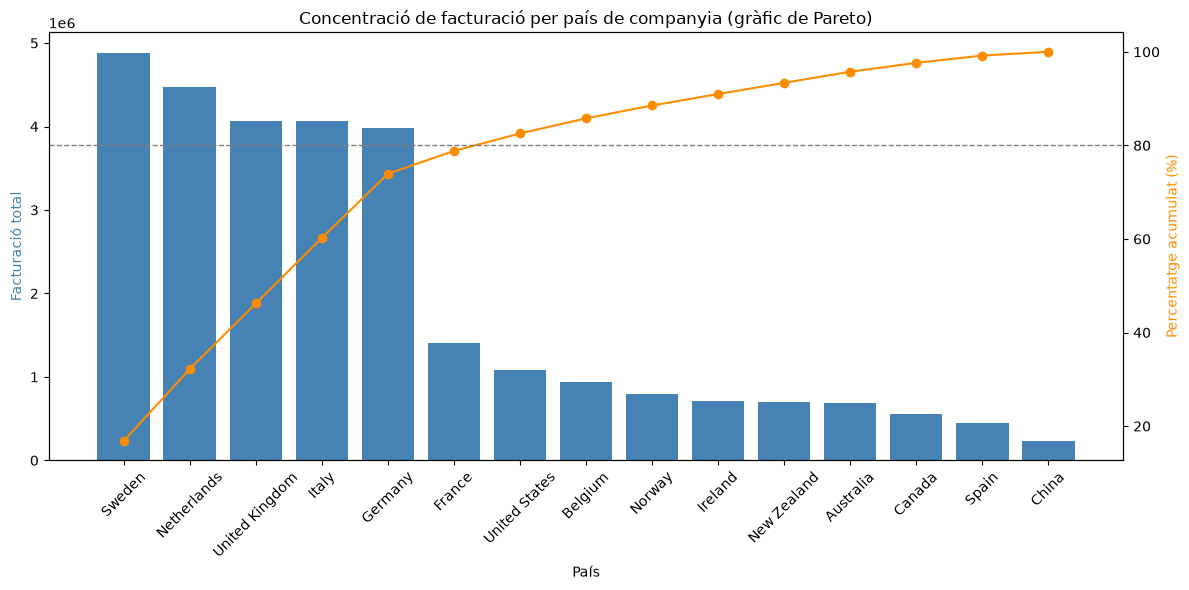

In [23]:
# dibuixo un gràfic de Pareto: barres amb la facturació per país i una línia amb el percentatge acumulat
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(resum_concentracio.index, resum_concentracio['facturacio'], color='steelblue')
ax1.set_xlabel('País')
ax1.set_ylabel('Facturació total', color='steelblue')
ax1.tick_params(axis='x', rotation=45)

# creo un segon eix Y que comparteix el mateix eix X, per a la línia de percentatge acumulat
ax2 = ax1.twinx()
ax2.plot(resum_concentracio.index, resum_concentracio['percentatge_acumulat'], color='darkorange', marker='o')
ax2.set_ylabel('Percentatge acumulat (%)', color='darkorange')
ax2.axhline(80, color='gray', linestyle='--', linewidth=1)

plt.title('Concentració de facturació per país de companyia (gràfic de Pareto)')
plt.tight_layout()
plt.show()

**Interpretació**

Sí, existeix una dependència significativa d'un nombre reduït de països: els 5 primers (Sweden, Netherlands, United Kingdom, Italy i Germany) ja concentren el 73.86% de tota la facturació, i amb el sisè (France) s'arriba al 78.69% — pràcticament el llindar clàssic del 80/20. En canvi, els 9 països restants (des de United States fins a la Xina) aporten conjuntament només un 21% del total, amb la Xina representant menys de l'1%.

Aquesta concentració suposa un risc de negoci: qualsevol afectació en un dels 5-6 països principals (canvis regulatoris, entrada de competència local, crisi econòmica) tindria un impacte desproporcionat sobre la facturació global, mentre que la resta de mercats actuen més aviat com a diversificació marginal que com a pilars reals del negoci.

#### Pregunta 2 — Existeix estacionalitat en les vendes?

**Algoritme:**
1. Extrec l'any i el mes de cada transacció a partir del `timestamp`.
2. Calculo el volum total de vendes (suma d'`amount`) per any i mes.
3. Construeixo una taula pivot amb els mesos com a files i els anys com a columnes, per poder comparar el mateix mes entre diferents anys.
4. Visualitzo l'evolució amb un gràfic que permeti veure si es repeteix el mateix patró any rere any.

In [24]:
# extrec l'any i el mes (numèric) de cada transacció
df_transaccions['any'] = df_transaccions['timestamp'].dt.year
df_transaccions['mes_num'] = df_transaccions['timestamp'].dt.month

# construeixo la taula pivot: un mes per fila, un any per columna, i la suma de vendes a cada cel·la
pivot_estacionalitat = df_transaccions[df_transaccions['declined'] == 0].pivot_table(
    index='mes_num', 
    columns='any', 
    values='amount', 
    aggfunc='sum'
)

pivot_estacionalitat

any,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mes_num,,,,,,,,,,
1,221978.21,224451.27,222956.21,227411.90,222944.11,231702.95,243339.85,224709.53,228413.66,226393.73
2,245780.13,248112.42,252303.71,245092.09,259807.32,248318.04,257434.31,235427.85,251422.67,249898.07
3,253000.65,246634.37,237621.09,237099.83,276818.21,258872.56,250861.14,271978.12,241711.00,245792.02
4,245597.21,240833.04,251596.72,234246.30,242707.81,244251.90,259770.51,237165.49,241264.06,244769.15
5,248585.36,241306.84,240125.80,244448.97,242550.42,253699.74,239662.08,276262.60,261355.45,254122.62
6,232624.35,230577.43,240337.61,242769.22,241694.85,236410.96,234080.71,260082.37,232254.56,244370.81
7,241252.27,237081.73,240576.35,231261.73,233513.25,240255.64,251450.91,233349.01,238652.72,230031.53
8,233797.97,235600.88,230225.76,228759.89,237070.53,232658.86,237051.75,245198.95,237981.15,236671.63
9,227211.93,241530.84,230606.28,236768.38,232551.83,257964.96,245398.37,254316.72,234226.30,234226.89


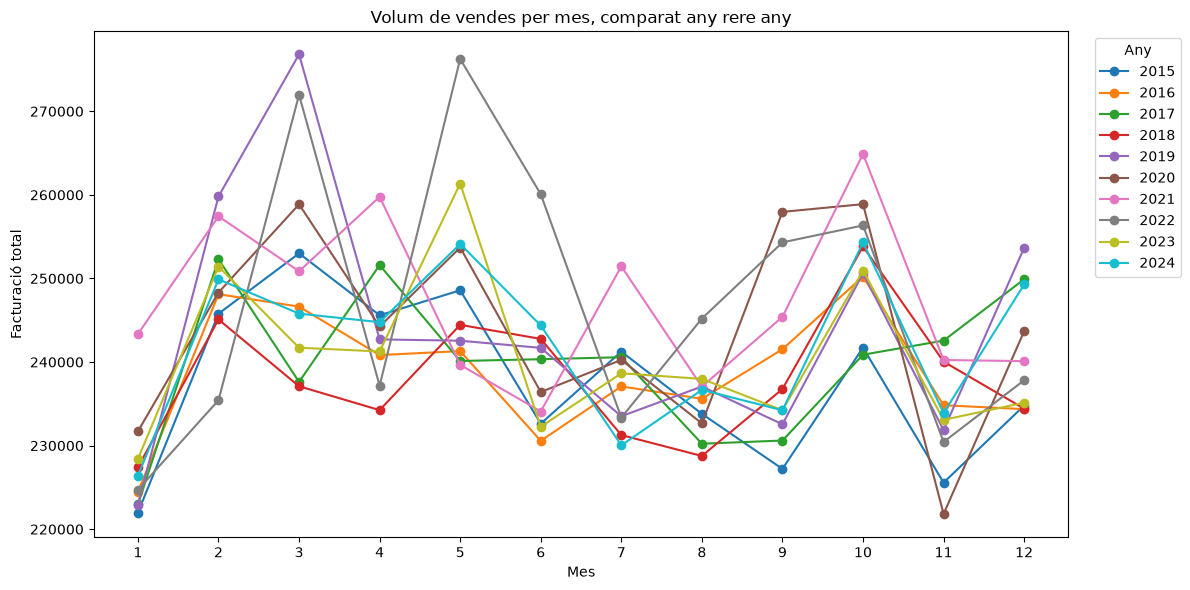

In [25]:
# dibuixo una línia per cada any, per veure si el patró mensual es repeteix
plt.figure(figsize=(12, 6))
for any_ in pivot_estacionalitat.columns:
    plt.plot(pivot_estacionalitat.index, pivot_estacionalitat[any_], marker='o', label=str(any_))

plt.title('Volum de vendes per mes, comparat any rere any')
plt.xlabel('Mes')
plt.ylabel('Facturació total')
plt.xticks(range(1, 13))
plt.legend(title='Any', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [26]:
# calculo la mitjana de cada mes al llarg dels 10 anys, per detectar el patró general sense el soroll any a any
mitjana_per_mes = pivot_estacionalitat.mean(axis=1).round(2)
mitjana_per_mes

mes_num
1     227430.14
2     249359.66
3     252038.90
4     244220.22
5     250211.99
6     239520.29
7     237742.51
8     235501.74
9     239480.25
10    252264.14
11    233434.29
12    241316.86
dtype: float64

**Interpretació**

S'observa una estacionalitat suau però consistent: el gener és sistemàticament el mes amb menys facturació any rere any (mitjana ~230k€, coherent amb un "efecte rebot" post-festes de Nadal/Reis), mentre que febrer, març i octubre es repeteixen com els mesos de més volum (mitjanes ~251-255k€). La resta de mesos es mouen en un rang força estable, sense pics ni caigudes dràstiques.

La magnitud d'aquesta estacionalitat és moderada: la diferència entre el mes més fort i el més fluix és d'aproximadament un 10-11%, no un canvi radical. És un patró prou consistent com per tenir-lo en compte en la planificació (per exemple, no esperar creixement al gener si el patró es manté), però no prou marcat per parlar d'un negoci fortament estacional com podria ser-ho el turisme d'estiu o el comerç nadalenc.

#### Pregunta 3 — Quins productes generen més ingressos i amb quina variabilitat?

**Algoritme:**
1. Combino transaccions amb la taula pont de productes (`product_ids`, que conté diversos productes per transacció) i amb la taula `products`.
2. Calculo els ingressos totals per producte amb un `groupby`, `sum` i `sort`.
3. Selecciono els 15 productes amb més ingressos.
4. Escullo una visualització que permeti veure tant els ingressos com la seva variabilitat (dispersió).

In [27]:
# carrego la taula de productes des de MySQL
df_products = pd.read_sql("SELECT * FROM products;", motor)
df_products.head()

,id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,1,Direwolf Stannis,$161.11,#7c7c7c,1.0,WH-4,Sports,Runway Pro,$63.84,2014-11-01
1,2,Tarly Stark,$9.24,#919191,2.0,WH-3,Gaming,Questbyte,$4.74,2013-02-07
2,3,duel tourney Lannister,$171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,$107.07,2013-08-18
3,4,warden south duel,$71.89,#111111,3.0,WH-1,Books,NorthPress,$39.17,2013-12-31
4,5,skywalker ewok,$171.22,#dbdbdb,3.2,WH-0,Home,NordHaus,$83.69,2014-07-17


In [28]:
# converteixo el text "16, 26, 97, 87" en una llista de números per a cada transacció
df_transaccions['llista_productes'] = df_transaccions['product_ids'].str.split(',')

# "esclato" la llista: cada producte d'una transacció passa a tenir la seva pròpia fila
df_productes_transaccio = df_transaccions.explode('llista_productes')

# elimino espais sobrants i converteixo el codi de producte a número enter
df_productes_transaccio['product_id'] = df_productes_transaccio['llista_productes'].str.strip().astype(int)

print(f"Files després d'esclatar: {len(df_productes_transaccio)} (abans: {len(df_transaccions)})")
df_productes_transaccio[['id', 'product_ids', 'product_id']].head()

Files després d'esclatar: 253388 (abans: 99999)


,id,product_ids,product_id
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,"16, 26, 97, 87",16
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,"16, 26, 97, 87",26
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,"16, 26, 97, 87",97
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,"16, 26, 97, 87",87
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,"30, 11, 16, 81",30


In [29]:
# uneixo cada producte de cada transacció amb el seu preu i nom real
df_productes_transaccio = df_productes_transaccio.merge(df_products[['id', 'product_name', 'price']], left_on='product_id', right_on='id', suffixes=('', '_producte'))

# el preu ve com a text amb el símbol $ (per exemple "$161.11"): el converteixo a numèric
df_productes_transaccio['price'] = df_productes_transaccio['price'].str.replace('$', '', regex=False).astype(float)

In [30]:
# comprovo si cada nom de producte correspon sempre al mateix product_id i preu, o si n'hi ha diversos amagats sota el mateix nom
noms_amb_diversos_ids = df_products.groupby('product_name')['id'].nunique().sort_values(ascending=False)
print(f"Noms de producte que corresponen a més d'un product_id: {(noms_amb_diversos_ids > 1).sum()}")
noms_amb_diversos_ids.head(10)

Noms de producte que corresponen a més d'un product_id: 20


product_name
Winterfell                 4
dooku solo                 4
the duel                   4
Karstark Dorne             3
Direwolf Stannis           3
skywalker ewok             3
Karstark warden            3
the giantsblood maester    2
duel Direwolf              2
Direwolf Littlefinger      2
Name: id, dtype: int64

In [31]:
# agrupo per product_id (identificador real i únic), no pel nom, que pot repetir-se entre productes diferents
ingressos_per_producte = df_productes_transaccio.groupby('product_id').agg(
    product_name=('product_name', 'first'),
    ingressos_totals=('price', 'sum'),
    vendes=('price', 'count'),
    variabilitat=('price', 'std')
).sort_values('ingressos_totals', ascending=False)

# em quedo amb els 15 productes amb més ingressos
top15_productes = ingressos_per_producte.head(15)
top15_productes

,product_name,ingressos_totals,vendes,variabilitat
product_id,,,,
39,warden,505587.15,2571,0.0
64,Direwolf,502352.16,2568,0.0
67,Winterfell,500038.88,2552,0.0
15,Stannis warden,492525.15,2535,0.0
93,Littlefinger Tarly Stark,488241.00,2535,0.0
62,the duel,481608.06,2549,0.0
86,Stark kingsblood,478322.88,2528,0.0
63,Jade tatooine dooku,476353.08,2526,0.0
16,the duel warden,471813.28,2608,0.0


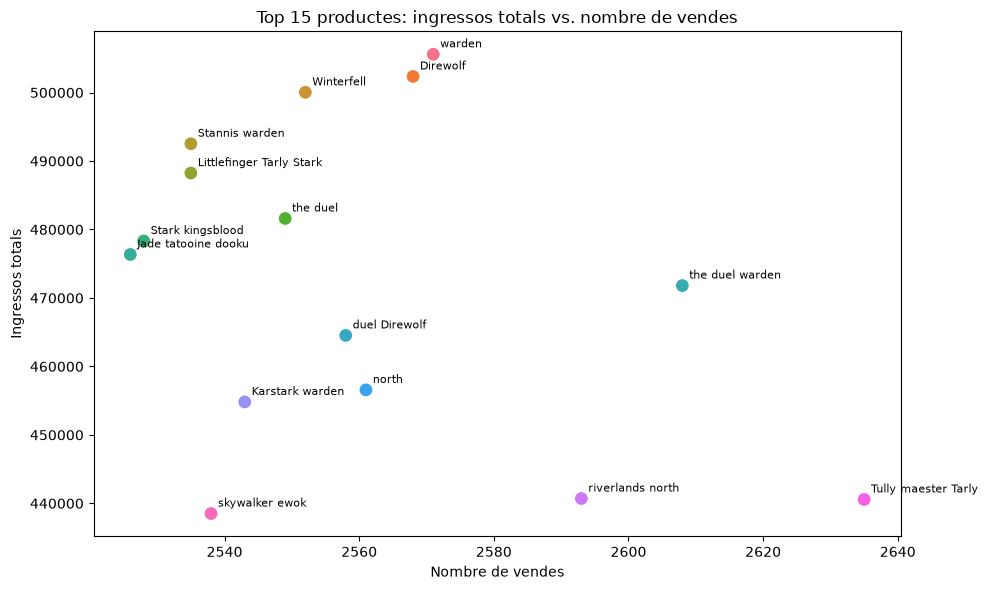

In [32]:
# dibuixo un scatter plot: ingressos totals vs. nombre de vendes, per veure la relació entre volum i facturació
plt.figure(figsize=(10, 6))
sns.scatterplot(data=top15_productes, x='vendes', y='ingressos_totals', hue='product_name', s=100, legend=False)

# afegeixo el nom de cada producte al costat del seu punt, ja que amb 15 productes una llegenda seria massa carregada
for _, fila in top15_productes.iterrows():
    plt.annotate(fila['product_name'], (fila['vendes'], fila['ingressos_totals']), fontsize=8, xytext=(5, 5), textcoords='offset points')

plt.title('Top 15 productes: ingressos totals vs. nombre de vendes')
plt.xlabel('Nombre de vendes')
plt.ylabel('Ingressos totals')
plt.tight_layout()
plt.show()

**Interpretació**

Entre els 15 productes amb més ingressos, el nombre de vendes és molt similar per a tots (entre 2526 i 2635 unitats), de manera que la diferència en ingressos totals ve determinada gairebé exclusivament pel **preu unitari** de cada producte, no pel volum de vendes: "warden" lidera amb 505.587€ tot i tenir un nombre de vendes dins la mitjana, perquè el seu preu unitari és el més alt del grup; en canvi, "skywalker ewok" tanca la llista malgrat vendre pràcticament el mateix nombre d'unitats que la resta.

Aquest patró (volum de vendes homogeni, ingressos diferenciats pel preu) suggereix que, per créixer en ingressos amb aquests productes top, la palanca més eficaç no és necessàriament vendre'n més unitats, sinó revisar l'estratègia de preus, o bé identificar per què productes amb preu similar a "warden" no arriben al mateix volum de vendes.

La variabilitat de preu és 0 en tots els casos, ja que cada producte té un preu fix per unitat: no hi ha, per tant, dispersió de preu a analitzar dins d'un mateix producte, sí entre productes diferents.

#### Pregunta 4 — Com varia l'activitat de venda per franges horàries al llarg dels anys?

**Algoritme:**
1. Creo una funció que classifica cada hora del dia en una franja horària (matí, tarda, vespre, nit), i l'aplico amb `apply`.
2. Construeixo una taula agregada amb `crosstab`, comptant transaccions per any i franja horària.
3. Visualitzo el resultat amb un heatmap.

In [33]:
# defineixo una funció que classifica cada hora en una franja horària del dia
def franja_horaria(hora):
    if 6 <= hora < 12:
        return 'Matí'
    if 12 <= hora < 18:
        return 'Tarda'
    if 18 <= hora < 24:
        return 'Vespre'
    return 'Nit'

# aplico la funció a la columna d'hora, ja calculada a la Pregunta 3 de l'Exercici 1
df_transaccions['franja'] = df_transaccions['hora'].apply(franja_horaria)

In [34]:
# defineixo l'ordre lògic de les franges, per no mostrar-les en ordre alfabètic
ordre_franges = ['Matí', 'Tarda', 'Vespre', 'Nit']

# construeixo la taula creuada: nombre de transaccions per any (files) i franja horària (columnes)
taula_franges = pd.crosstab(df_transaccions['any'], df_transaccions['franja'])[ordre_franges]

taula_franges

franja,Matí,Tarda,Vespre,Nit
any,,,,
2015,2461,2457,2500,2452
2016,2481,2510,2389,2474
2017,2476,2554,2441,2444
2018,2425,2508,2456,2523
2019,2554,2544,2450,2467
2020,2471,2472,2535,2615
2021,2584,2593,2532,2589
2022,2457,2520,2560,2569
2023,2551,2464,2454,2516


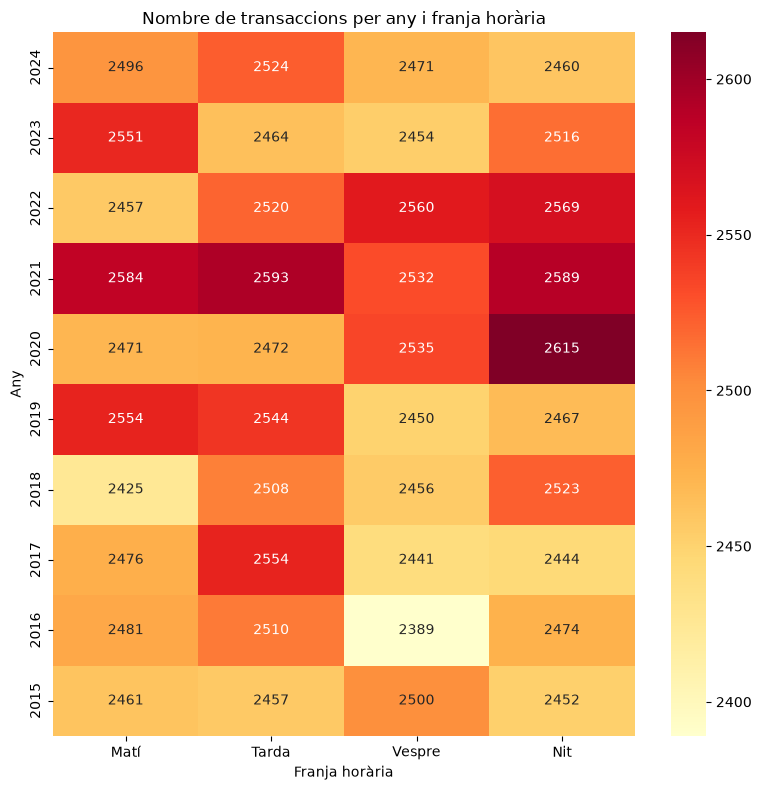

In [35]:
# inverteixo l'ordre de les files perquè l'any més recent quedi a dalt
taula_franges_invertida = taula_franges.sort_index(ascending=False)

# dibuixo un heatmap: com més fosc el color, més transaccions en aquella combinació d'any i franja horària
plt.figure(figsize=(8, 8))
sns.heatmap(taula_franges_invertida, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Nombre de transaccions per any i franja horària')
plt.xlabel('Franja horària')
plt.ylabel('Any')
plt.tight_layout()
plt.show()

**Interpretació**

L'activitat es reparteix de manera molt homogènia entre les quatre franges horàries i els deu anys, sense cap patró marcat: els valors oscil·len entre 2389 i 2615 transaccions per combinació any-franja, una diferència de només un 9% entre el mínim i el màxim de tota la taula. No s'identifica cap franja horària que concentri sistemàticament més activitat any rere any (per exemple, "Nit" és la franja més alta el 2018 i el 2020, però la més baixa el 2015 i el 2024), ni cap tendència clara d'un any a un altre.

Aquesta homogeneïtat és coherent amb el que ja vam observar a la Pregunta 4 de l'Exercici 1 (repartiment molt uniforme entre dies de la setmana): el negoci sembla tenir un patró de consum molt constant en el temps, sense franges horàries ni dies "crítics" evidents en volum de transaccions.

## Nivell 2 - Anàlisi relacional i patrons avançats

### Exercici 1 — Anàlisi de productes i captació d'usuaris

Els productes que més facturen no són necessàriament els que aporten més valor estratègic al negoci: cal distingir entre productes que atreuen usuaris nous i productes que només es venen a la base de clients ja existent, per detectar riscos de dependència d'usuaris recurrents i manca de creixement.

**Algoritme:**
1. Combino transaccions (ja esclatades per producte) amb la informació d'usuaris.
2. Per a cada usuari, identifico quina és la seva primera transacció cronològica al sistema.
3. Marco cada transacció com a `es_nou_usuari = True` si és la primera del seu usuari, `False` en cas contrari.
4. Agrego per producte: ingressos totals, variabilitat, nombre de nous usuaris captats i percentatge de nous usuaris sobre el total de compradors.
5. Defineixo una tipologia de producte (Captador, Recurrent, Emergent, Estancat) a partir d'aquestes mètriques.
6. Visualitzo amb un scatter plot: ingressos (X), nous usuaris (Y), variabilitat (mida), tipologia (color).

In [36]:
# per a cada usuari, identifico la data de la seva primera transacció al sistema
primera_transaccio_usuari = df_transaccions.groupby('user_id')['timestamp'].transform('min')

# marco com a nou usuari les transaccions on la data coincideix amb la primera transacció d'aquell usuari
df_transaccions['es_nou_usuari'] = df_transaccions['timestamp'] == primera_transaccio_usuari

print(f"Transaccions de nous usuaris: {df_transaccions['es_nou_usuari'].sum()} de {len(df_transaccions)}")

Transaccions de nous usuaris: 5000 de 99999


In [37]:
# torno a esclatar product_ids per tenir una fila per producte i transacció, ara amb es_nou_usuari inclòs
df_prod_usuaris = df_transaccions.copy()
df_prod_usuaris['llista_productes'] = df_prod_usuaris['product_ids'].str.split(',')
df_prod_usuaris = df_prod_usuaris.explode('llista_productes')
df_prod_usuaris['product_id'] = df_prod_usuaris['llista_productes'].str.strip().astype(int)

# uneixo amb products per tenir el nom
df_prod_usuaris = df_prod_usuaris.merge(df_products[['id', 'product_name']], left_on='product_id', right_on='id', suffixes=('', '_prod'))

# agrego per producte: ingressos totals, variabilitat, compradors totals i nous usuaris captats
resum_productes = df_prod_usuaris.groupby('product_id').agg(
    product_name=('product_name', 'first'),
    ingressos_totals=('amount', 'sum'),
    variabilitat=('amount', 'std'),
    compradors_totals=('user_id', 'count'),
    nous_usuaris=('es_nou_usuari', 'sum')
)

# calculo el percentatge de nous usuaris sobre el total de compradors del producte
resum_productes['pct_nous_usuaris'] = (resum_productes['nous_usuaris'] / resum_productes['compradors_totals'] * 100).round(2)

resum_productes.sort_values('ingressos_totals', ascending=False).head(10)

,product_name,ingressos_totals,variabilitat,compradors_totals,nous_usuaris,pct_nous_usuaris
product_id,,,,,,
39,warden,1154841.34,147.557874,2571,121,4.71
67,Winterfell,1154360.96,150.064281,2552,120,4.70
64,Direwolf,1152983.78,152.768655,2568,117,4.56
12,duel Direwolf,1137696.37,161.951347,2558,126,4.93
15,Stannis warden,1131994.63,151.398508,2535,124,4.89
93,Littlefinger Tarly Stark,1130606.39,150.376519,2535,108,4.26
16,the duel warden,1130601.86,148.434659,2608,131,5.02
62,the duel,1129275.97,152.834840,2549,108,4.24
86,Stark kingsblood,1116933.98,149.759191,2528,112,4.43


In [38]:
# calculo les medianes de referència sobre TOTS els productes (no només el top 10), per definir llindars relatius
mediana_ingressos = resum_productes['ingressos_totals'].median()
mediana_pct_nous = resum_productes['pct_nous_usuaris'].median()

def classifica_producte(fila):
    ingressos_alts = fila['ingressos_totals'] >= mediana_ingressos
    captacio_alta = fila['pct_nous_usuaris'] >= mediana_pct_nous

    if ingressos_alts and captacio_alta:
        return 'Captador'
    if ingressos_alts and not captacio_alta:
        return 'Recurrent'
    if not ingressos_alts and captacio_alta:
        return 'Emergent'
    return 'Estancat'

resum_productes['tipologia'] = resum_productes.apply(classifica_producte, axis=1)

resum_productes['tipologia'].value_counts()

tipologia
Recurrent    29
Emergent     29
Estancat     21
Captador     21
Name: count, dtype: int64

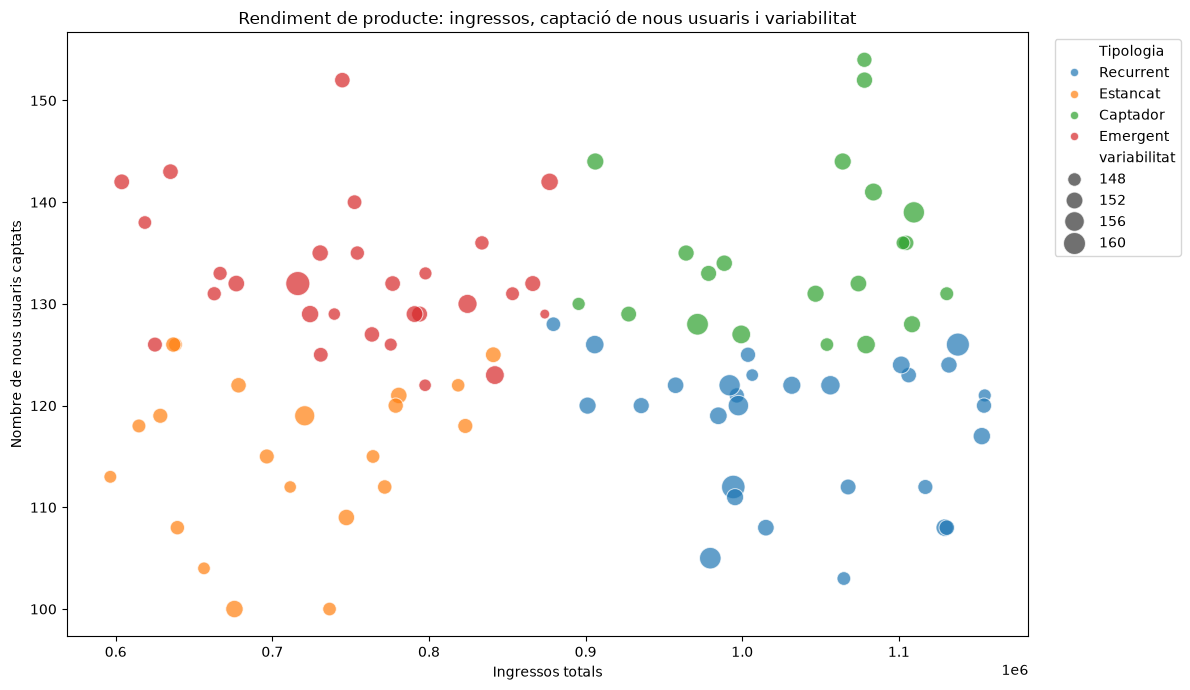

In [39]:
# dibuixo el scatter plot: ingressos (X), nous usuaris (Y), variabilitat (mida del punt), tipologia (color)
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=resum_productes,
    x='ingressos_totals',
    y='nous_usuaris',
    size='variabilitat',
    hue='tipologia',
    sizes=(50, 300),
    alpha=0.7
)
plt.title('Rendiment de producte: ingressos, captació de nous usuaris i variabilitat')
plt.xlabel('Ingressos totals')
plt.ylabel('Nombre de nous usuaris captats')

# capitalitzo el títol de cada bloc de la llegenda perquè es distingeixin millor
legenda = plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
legenda.get_texts()[0].set_text('Tipologia')

plt.tight_layout()
plt.show()

**Interpretació de negoci**

La captació de nous usuaris és molt baixa i pràcticament uniforme a tot el catàleg: entre els productes top per ingressos, només un 4-5% dels compradors són usuaris nous, sense diferències substancials entre ells. Això es reflecteix en la classificació: els 100 productes es reparteixen de manera força equilibrada entre les 4 tipologies (21-29 productes cadascuna), sense que cap categoria domini clarament sobre les altres.

**El negoci depèn principalment d'usuaris recurrents, no de la captació de nous usuaris a través del catàleg de productes.** Els productes classificats com "Recurrent" (ingressos alts, captació baixa) generen una facturació sòlida, però ho fan revenent als mateixos ~2500 compradors per producte, no ampliant la base de clients. Cap producte del top d'ingressos destaca com un motor real de creixement (una "porta d'entrada" que atregui volums significatius d'usuaris nous).

**Risc detectat:** si el ritme d'entrada de nous usuaris es manté en aquest ~5% de manera estructural (no és un efecte puntual d'algun producte concret, sinó un patró de tot el catàleg), el creixement futur del negoci dependrà gairebé exclusivament de vendre més als clients actuals (upselling/cross-selling), no de créixer en volum de base de clients — una estratègia amb sostre, ja que la despesa d'un client recurrent no és il·limitada. Convindria investigar per què el catàleg actual no capta usuaris nous: si és un problema d'adquisició (màrqueting) o del propi mix de productes (cap producte "gateway" atractiu per a nouvinguts).

### Exercici 2 — Anàlisi geogràfica company-usuari i oportunitats d'expansió

Entendre si el negoci funciona majoritàriament amb compres locals (usuari i companyia del mateix país) o si hi ha un flux real de compra internacional permet detectar oportunitats d'expansió: països amb demanda d'usuaris però poca oferta local de companyies.


**Algoritme:**
1. Combino transaccions amb el país de la companyia (ja el tenim) i amb el país de l'usuari (cal carregar la taula d'usuaris).
2. Creo la variable `compra_local` (True si usuari i companyia són del mateix país).
3. Calculo el percentatge de transaccions i de facturació locals vs. internacionals, a nivell global.
4. Per a cada país d'usuari, calculo el percentatge de compres locals vs. estrangeres i l'import total comprat.
5. Per a cada país de companyia, calculo quina part de la seva facturació ve d'usuaris locals vs. estrangers.
6. Visualitzo el fenomen amb un gràfic adequat.
7. Interpreto oportunitats d'expansió i riscos de dependència.

In [40]:
# carrego la taula d'usuaris des de MySQL
df_users = pd.read_sql("SELECT * FROM users;", motor)
df_users.head()

,id,name,surname,phone,email,birth_date,country,city,postal_code,address,signup_date,user_segment,income_band
0,1,Zeus,Gamble,1-282-581-0551,interdum.enim@protonmail.edu,"Nov 17, 1985",United States,New York,10001,348-7818 Sagittis St.,2014-04-23,young_professional,high
1,2,Garrett,Mcconnell,(718) 257-2412,integer.vitae.nibh@protonmail.org,"Aug 23, 1992",United States,Philadelphia,19101,903 Sit Ave,2014-07-04,young_professional,high
2,3,Ciaran,Harrison,(522) 598-1365,interdum.feugiat@aol.org,"Apr 29, 1998",United States,Houston,77001,736-2063 Tellus St.,2014-02-15,frequent_shopper,high
3,4,Howard,Stafford,1-411-740-3269,ornare.egestas@icloud.edu,"Feb 18, 1989",United States,Phoenix,85001,Ap #545-2244 Erat. Rd.,2014-08-21,premium,high
4,5,Hayfa,Pierce,1-554-541-2077,et.malesuada.fames@hotmail.org,"Sep 26, 1998",United States,Philadelphia,19101,341-2821 Ultrices Av.,2013-04-28,frequent_shopper,high


In [41]:
# uneixo transaccions (ja amb el país de companyia) amb el país de l'usuari
df_geo = df_transaccions_companies.merge(
    df_users[['id', 'country']], left_on='user_id', right_on='id', suffixes=('_companyia', '_usuari')
)

# comprovo que no hi hagi transaccions sense usuari aparellat
print(f"Transaccions sense usuari aparellat: {df_geo['country_usuari'].isnull().sum()}")

# creo la variable clau: compra_local és True si l'usuari i la companyia són del mateix país
df_geo['compra_local'] = df_geo['country_companyia'] == df_geo['country_usuari']

df_geo[['user_id', 'country_usuari', 'business_id', 'country_companyia', 'compra_local']].head()

Transaccions sense usuari aparellat: 0


,user_id,country_usuari,business_id,country_companyia,compra_local
0,4713,France,b-2458,Netherlands,False
1,2118,United States,b-2390,Ireland,False
2,2115,Canada,b-2230,United States,False
3,3025,Netherlands,b-2266,Sweden,False
4,215,Canada,b-2598,Belgium,False


In [42]:
# calculo el percentatge de transaccions locals vs. internacionals
pct_transaccions = df_geo['compra_local'].value_counts(normalize=True).round(4) * 100
print("Percentatge de transaccions:")
print(pct_transaccions)

# calculo el percentatge de facturació local vs. internacional
facturacio_local_vs_internacional = df_geo.groupby('compra_local')['amount'].sum()
pct_facturacio = (facturacio_local_vs_internacional / facturacio_local_vs_internacional.sum() * 100).round(2)
print("\nPercentatge de facturació:")
print(pct_facturacio)

Percentatge de transaccions:
compra_local
False    88.14
True     11.86
Name: proportion, dtype: float64

Percentatge de facturació:
compra_local
False    88.13
True     11.87
Name: amount, dtype: float64


In [43]:
# per a cada país d'usuari, calculo el percentatge de compres locals/estrangeres i l'import total comprat
analisi_per_usuari = df_geo.groupby('country_usuari').agg(
    total_comprat=('amount', 'sum'),
    n_transaccions=('amount', 'count'),
    pct_local=('compra_local', 'mean')
)
analisi_per_usuari['pct_local'] = (analisi_per_usuari['pct_local'] * 100).round(2)
analisi_per_usuari['pct_internacional'] = (100 - analisi_per_usuari['pct_local']).round(2)

analisi_per_usuari.sort_values('total_comprat', ascending=False)

,total_comprat,n_transaccions,pct_local,pct_internacional
country_usuari,,,,
United States,3091289.85,11496,18.54,81.46
United Kingdom,2838889.37,9647,17.29,82.71
Spain,2693566.24,8960,1.74,98.26
Canada,2688940.83,9986,9.71,90.29
Netherlands,2675165.65,8961,19.32,80.68
Portugal,2638023.31,8765,0.00,100.00
Italy,2603393.17,8565,17.10,82.90
Germany,2573251.67,8723,16.94,83.06
Poland,2512973.74,8274,0.00,100.00


In [44]:
# per a cada país de companyia, calculo quina part de la seva facturació ve d'usuaris locals vs. estrangers
analisi_per_companyia = df_geo.groupby('country_companyia').agg(
    facturacio_total=('amount', 'sum'),
    n_transaccions=('amount', 'count'),
    pct_usuaris_locals=('compra_local', 'mean')
)
analisi_per_companyia['pct_usuaris_locals'] = (analisi_per_companyia['pct_usuaris_locals'] * 100).round(2)
analisi_per_companyia['pct_usuaris_estrangers'] = (100 - analisi_per_companyia['pct_usuaris_locals']).round(2)

analisi_per_companyia.sort_values('facturacio_total', ascending=False)

,facturacio_total,n_transaccions,pct_usuaris_locals,pct_usuaris_estrangers
country_companyia,,,,
Sweden,4928117.68,16512,10.47,89.53
Netherlands,4506571.38,15055,11.50,88.50
United Kingdom,4099117.08,13776,12.11,87.89
Italy,4087557.38,13668,10.72,89.28
Germany,4020364.07,13291,11.12,88.88
France,1416084.26,4700,11.36,88.64
United States,1101737.27,4036,52.80,47.20
Belgium,952208.75,3531,0.00,100.00
Norway,809288.82,3030,0.00,100.00


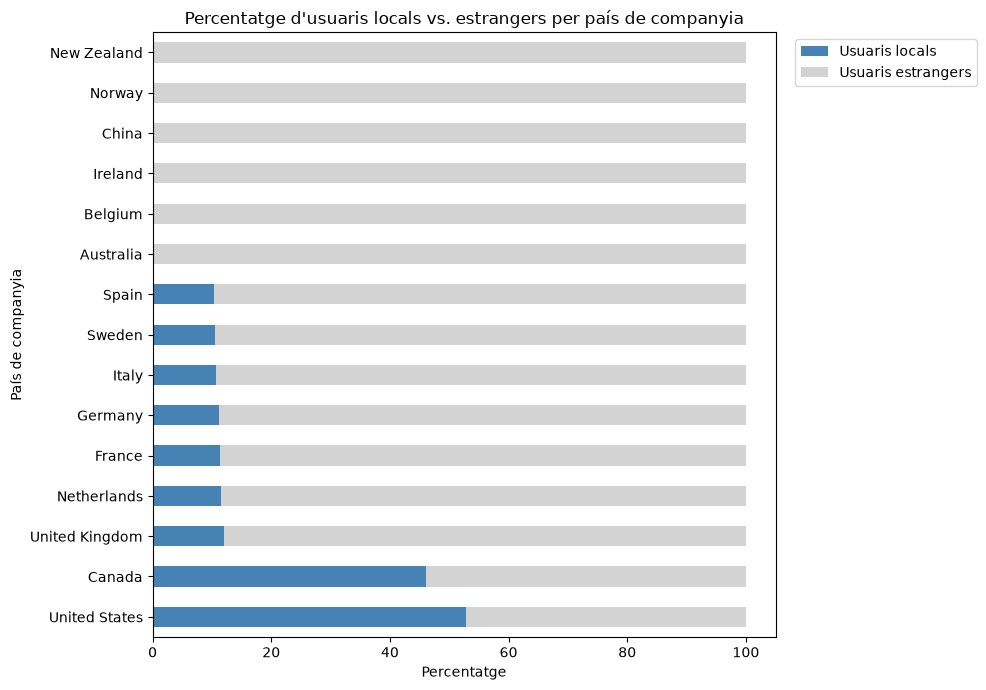

In [45]:
# comparo, per país de companyia, el percentatge d'usuaris locals vs. estrangers amb un gràfic de barres apilades
dades_grafic = analisi_per_companyia[['pct_usuaris_locals', 'pct_usuaris_estrangers']].sort_values('pct_usuaris_locals', ascending=False)

dades_grafic.plot(kind='barh', stacked=True, figsize=(10, 7), color=['steelblue', 'lightgray'])
plt.title("Percentatge d'usuaris locals vs. estrangers per país de companyia")
plt.xlabel('Percentatge')
plt.ylabel('País de companyia')
plt.legend(['Usuaris locals', 'Usuaris estrangers'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretació estratègica**

El negoci és majoritàriament **internacional, no local**: només un 11.86% de les transaccions (i un 11.87% de la facturació) es fan entre un usuari i una companyia del mateix país — pràcticament idèntic als dos indicadors, cosa que descarta que el patró es degui a diferències d'import entre compres locals i internacionals.

**Oportunitats d'expansió detectades:**
- **Portugal, Polònia, Belgium, Norway, Ireland, New Zealand, Australia i Xina tenen un 0% de compres locals** perquè, comprovant-ho amb el llistat de països de companyia, cap d'aquests països hi apareix (excepte Belgium, Norway, Ireland, New Zealand i Australia, que sí tenen companyies però un 0% d'usuaris locals que hi comprin — un símptoma diferent: no és manca d'oferta, és manca de conversió local). En canvi, Portugal, Polònia i Xina (aquest últim sí amb companyia, però 0% d'ús local) combinen demanda d'usuaris (apareixen a l'anàlisi per usuari) amb absència total de compra local, fent-los els candidats més clars per avaluar l'obertura de companyies pròpies o per investigar per què l'oferta local existent (a Belgium, Norway, Ireland, New Zealand, Australia) no capta ni un sol comprador del mateix país.
- **United States i Canada són l'excepció clara**: amb un 52.80% i 46.04% d'usuaris locals respectivament, funcionen de manera molt diferent a la resta del negoci, més proper a un mercat domèstic real que a un de majoritàriament d'exportació.

**Risc de dependència:** els 5 països de companyia amb més facturació (Sweden, Netherlands, UK, Italy, Germany — ja detectats a la Pregunta 1 de l'Exercici 2 del Nivell 1 com el 73.86% de tota la facturació) depenen gairebé per complet d'usuaris estrangers (88-89% en tots ells). Això significa que aquestes companyies clau no depenen d'una base de clients local pròpia, sinó del flux internacional — una estructura de negoci que funciona bé mentre el comerç transfronterer flueixi sense fricció, però que quedaria molt exposada davant de canvis regulatoris al comerç internacional (aranzels, restriccions duaneres, normatives de protecció de dades entre països) que un negoci amb base local sòlida no patiria igual.

**Recomanació:** el patró de United States (mercat amb base local real) sembla una excepció a replicar, no la norma; convindria investigar què fa diferent aquest mercat (regulació, mida del país, preferència del consumidor per comprar local) per valorar si es pot reproduir en algun dels països amb demanda d'usuaris però sense oferta local pròpia.

## Nivell 3 - Visualització executiva i storytelling

### Exercici 1 — Mini-dashboard departamental

**Departament escollit: Vendes / Comercial.**

Un dashboard per a l'equip comercial ha de respondre ràpidament quatre preguntes clau: com evoluciona el volum de negoci, quins mercats el sostenen, quins productes el generen, i quina part de les vendes s'estan perdent per rebuigs.

**Mètriques seleccionades (1 figura, 4 subplots):**
1. Evolució mensual de la facturació (tendència global del negoci).
2. Top 10 països de companyia per facturació (concentració geogràfica).
3. Top 10 productes per ingressos (quins productes sostenen les vendes).
4. Percentatge de transaccions rebutjades per any (vendes perdudes).

**Algoritme:**
1. Reutilitzo els càlculs ja fets a nivells anteriors per a cada mètrica (facturació mensual, facturació per país, ingressos per producte).
2. Calculo el percentatge de transaccions rebutjades per any, una mètrica encara no calculada.
3. Construeixo una única figura amb 4 subplots (graella 2x2), cadascun amb la seva visualització.

In [46]:
# calculo el percentatge de transaccions rebutjades per any
rebuig_per_any = df_transaccions.groupby('any')['declined'].mean() * 100
rebuig_per_any = rebuig_per_any.round(2)
rebuig_per_any

any
2015    0.94
2016    0.86
2017    0.83
2018    0.90
2019    0.87
2020    0.83
2021    0.97
2022    0.90
2023    0.83
2024    0.94
Name: declined, dtype: float64

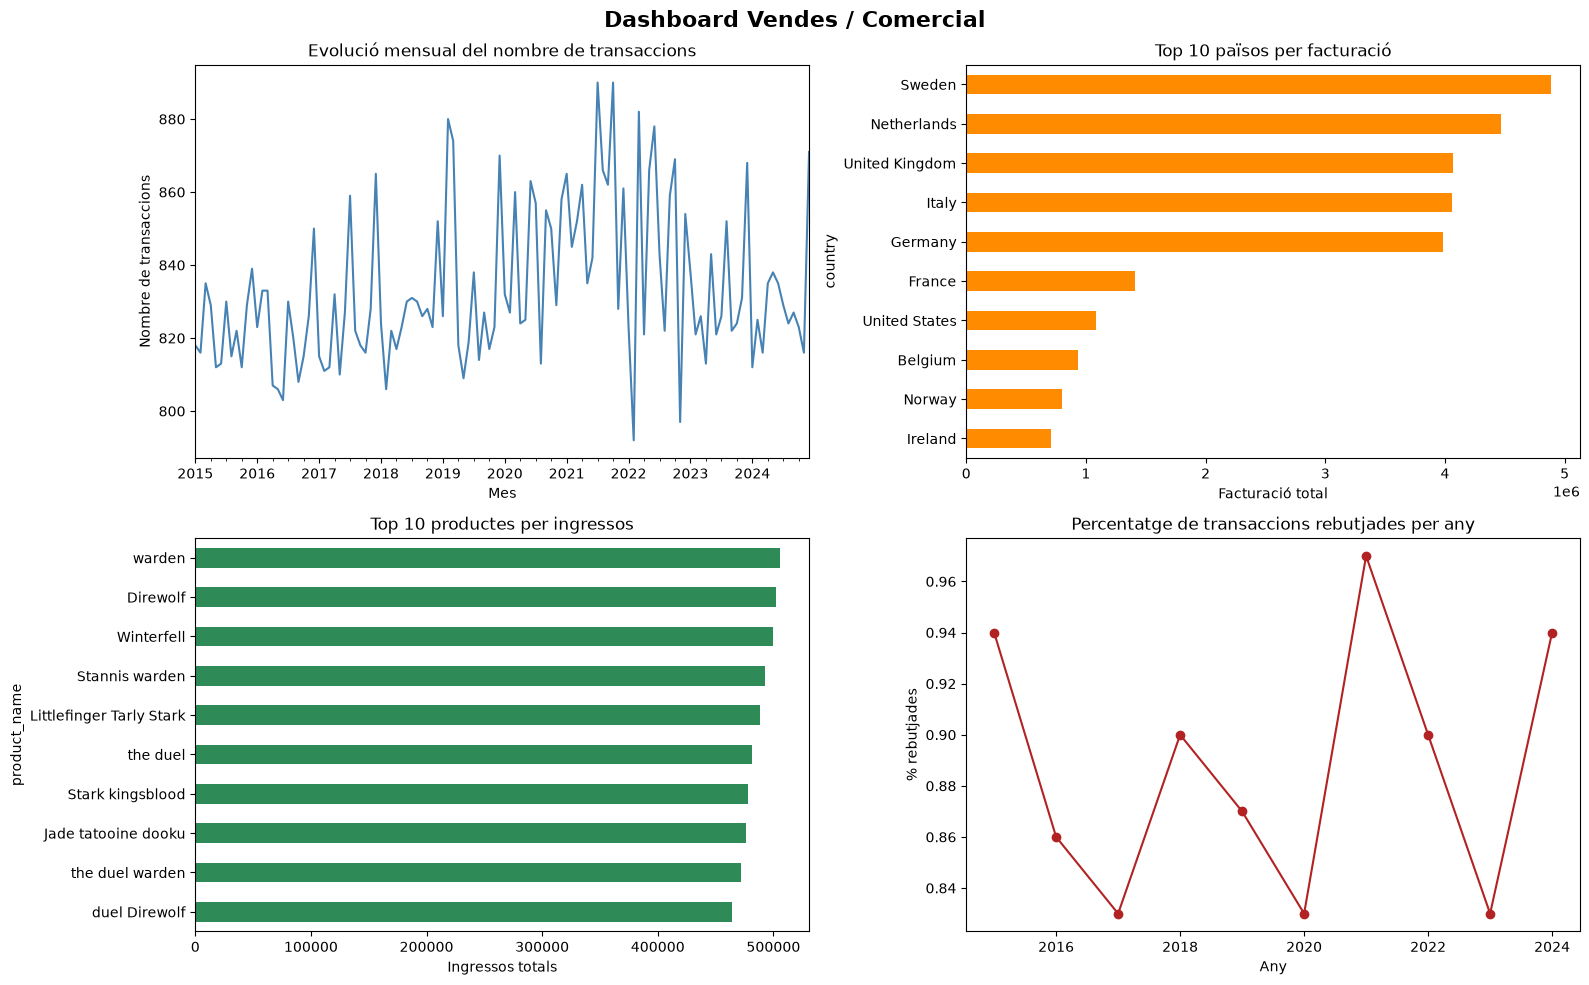

In [47]:
# construeixo una única figura amb una graella de 2x2 subplots per al dashboard de Vendes/Comercial
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Dashboard Vendes / Comercial', fontsize=16, fontweight='bold')

# subplot 1 (dalt esquerra): evolució mensual de la facturació
transaccions_per_mes.plot(kind='line', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Evolució mensual del nombre de transaccions')
axes[0, 0].set_xlabel('Mes')
axes[0, 0].set_ylabel('Nombre de transaccions')

# subplot 2 (dalt dreta): top 10 països per facturació
facturacio_per_pais.head(10).plot(kind='barh', ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title('Top 10 països per facturació')
axes[0, 1].set_xlabel('Facturació total')
axes[0, 1].invert_yaxis()

# subplot 3 (baix esquerra): top 10 productes per ingressos
top15_productes.head(10).set_index('product_name')['ingressos_totals'].plot(kind='barh', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Top 10 productes per ingressos')
axes[1, 0].set_xlabel('Ingressos totals')
axes[1, 0].invert_yaxis()

# subplot 4 (baix dreta): percentatge de rebuig per any
rebuig_per_any.plot(kind='line', ax=axes[1, 1], color='firebrick', marker='o')
axes[1, 1].set_title('Percentatge de transaccions rebutjades per any')
axes[1, 1].set_xlabel('Any')
axes[1, 1].set_ylabel('% rebutjades')

plt.tight_layout()
plt.show()

**Interpretació**

El dashboard combina les quatre mètriques que més interessen a l'equip comercial en una sola vista: el volum de negoci es manté estable mes rere mes sense senyals de creixement ni de declivi; la facturació es concentra clarament en 5 dels 15 països de companyia (Sweden, Netherlands, United Kingdom, Italy i Germany); els ingressos per producte estan força repartits entre el top 10, sense un producte estrella que destaqui molt per sobre de la resta; i els rebuigs es mantenen sempre per sota de l'1%, sense cap any que trenqui aquesta tendència.

En conjunt, aquestes quatre vistes retraten un negoci **estable i consolidat, però amb baixa capacitat de creixement orgànic**: ni el volum de transaccions ni la concentració geogràfica mostren senyals de canvi, i com ja s'ha vist als nivells anteriors, la manca de captació de nous usuaris reforça aquesta lectura. Els rebuigs baixos indiquen que l'operativa transaccional funciona bé; el repte no és operatiu, és de creixement i diversificació.

### Exercici 2 — Informe executiu

A partir del dashboard de Vendes/Comercial, es presenta un informe executiu en dues versions: una redactada directament, i una segona amb suport d'IA per millorar la redacció i incorporar vocabulari tècnic de negoci.

#### Informe executiu — Versió sense IA

**Resum general**
S'ha analitzat l'activitat transaccional de l'empresa entre 2015 i 2024 (100.000 transaccions) per entendre l'evolució del volum de vendes, la concentració geogràfica i de producte, i el pes dels rebuigs, amb l'objectiu de donar suport a la presa de decisions comercials.

**Troballes clau**
1. El volum de transaccions es manté molt estable any rere any (~800-870/mes), sense creixement ni caiguda.
2. Cinc països (Sweden, Netherlands, UK, Italy, Germany) concentren el 73.86% de tota la facturació.
3. Només un 4-5% dels compradors dels productes principals són usuaris nous; el negoci depèn sobretot de clients recurrents.
4. El 88% de les compres són internacionals (usuari i companyia de països diferents); només als Estats Units i Canadà hi ha un pes rellevant de compra local.
5. El percentatge de transaccions rebutjades és baix i estable (0.83%-0.97%).

**Riscos detectats**
- Dependència excessiva d'un grup reduït de països de companyia per a la facturació total.
- Manca de captació de nous usuaris al catàleg de productes principal, que limita el creixement futur si no es reforça l'adquisició.
- Estructura internacional molt exposada a canvis regulatoris en el comerç transfronterer.

**Oportunitats**
- Països amb demanda d'usuaris però sense oferta local (Portugal, Polònia, i companyies existents a Bèlgica, Noruega, Irlanda, Nova Zelanda i Austràlia sense conversió local) com a candidats a expansió.
- El patró d'Estats Units (mercat amb base local sòlida) com a model a replicar en altres mercats.
- Estabilitat del negoci com a base per planificar creixement, no només per mantenir el volum actual.

**Recomanacions**
- Explorar l'obertura de companyies locals a Portugal i Polònia, on hi ha demanda d'usuaris sense cap oferta pròpia.
- Investigar per què les companyies ja existents a Bèlgica, Irlanda, Noruega, Nova Zelanda i Austràlia no capten cap comprador local.
- Revisar l'estratègia de producte per identificar o crear productes "porta d'entrada" que captin més usuaris nous.
- Aprofitar l'estacionalitat detectada (gener més fluix, febrer/març/octubre més forts) en la planificació de campanyes comercials.

#### Informe executiu — Versió amb suport d'IA

**Resum general**
Anàlisi de l'activitat transaccional del període 2015-2024 (100.000 transaccions) orientada a l'equip de Vendes/Comercial, amb l'objectiu d'identificar palanques de creixement, riscos de concentració i oportunitats d'expansió geogràfica que orientin la presa de decisions comercials del proper exercici.

**Troballes clau**
1. El volum transaccional mostra una **estabilitat estructural** (~800-870 transaccions/mes) al llarg de la dècada, sense tendència de creixement orgànic detectable.
2. Existeix una **concentració de facturació elevada**: 5 mercats (Suècia, Països Baixos, Regne Unit, Itàlia i Alemanya) representen el 73,86% dels ingressos totals, superant el llindar de referència del principi de Pareto (80/20).
3. La **taxa de captació de nous clients** al catàleg de producte principal és baixa i homogènia (4-5%), evidenciant una dependència estructural d'usuaris recurrents més que de nova adquisició.
4. El **88% del volum de negoci és cross-border** (usuari i comerç de països diferents); Estats Units i Canadà són els únics mercats amb un component domèstic significatiu (>45% de compra local).
5. La **taxa de rebuig es manté sota control** (0,83%-0,97% anual), sense deteriorar-se en cap exercici, confirmant una operativa transaccional sòlida.

**Riscos detectats**
- **Risc de concentració geogràfica**: la dependència de 5 mercats per a gairebé tres quartes parts dels ingressos exposa el negoci a xocs localitzats (regulatoris, macroeconòmics o competitius) amb impacte desproporcionat sobre el conjunt.
- **Sostre de creixement per manca d'adquisició**: sense una millora en la captació de nous usuaris, el creixement futur dependrà gairebé en exclusiva de l'ampliació de la despesa (share of wallet) dels clients ja existents, una palanca amb recorregut limitat.
- **Exposició a fricció comercial internacional**: amb un 88% del negoci travessant fronteres, qualsevol canvi en aranzels, normativa duanera o regulació de protecció de dades transfronterera tindria un impacte estructural, no puntual.

**Oportunitats**
- **White spaces d'expansió**: Portugal i Polònia combinen demanda d'usuari acreditada amb absència total d'oferta local, posicionant-se com a candidats prioritaris per a l'obertura de nous comerços.
- **Conversió local infraexplotada**: Bèlgica, Irlanda, Noruega, Nova Zelanda i Austràlia ja compten amb oferta local instal·lada però registren un 0% de conversió domèstica — una oportunitat d'optimització sense necessitat d'inversió en nova infraestructura comercial.
- **Playbook replicable**: el model nord-americà (base de client local consolidada) pot servir de referència per dissenyar una estratègia de "localització" en mercats amb potencial similar.
- **Estacionalitat accionable**: el patró recurrent (gener com a vall, febrer/març/octubre com a pics) permet una planificació de campanyes i estoc més ajustada a la demanda real.

**Recomanacions**
1. Iniciar un estudi de viabilitat per a l'obertura de comerços propis a Portugal i Polònia, mercats amb demanda no atesa.
2. Auditar l'experiència de compra a Bèlgica, Irlanda, Noruega, Nova Zelanda i Austràlia per identificar barreres de conversió local (preu, logística, percepció de marca).
3. Redissenyar el mix de producte incorporant referències "porta d'entrada" orientades específicament a la captació de nou client.
4. Calendaritzar les campanyes comercials clau al voltant dels pics d'estacionalitat identificats (febrer, març i octubre), i reforçar accions de reactivació al gener.